# 21 – Prognose-LSTM: ein Wächter, der jeden Tag vorhersagt und bei Abweichung warnt

**Zweck:** Notebook 20 hat gezeigt, dass ein LSTM das Verhalten einer Station lernen
kann. Hier wird daraus ein **Überwacher**: Das Netz sagt jeden Tag voraus, wie Rücklauf
und Durchfluss einer Station morgen verlaufen sollten — aus der letzten Woche, dem
Wetterbericht und der Vorlauftemperatur des Netzes. Weicht die Station deutlich und
anhaltend davon ab, gibt es eine **Warnung**.

**Der Unterschied zu Notebook 20 und 22:** Dort geht es um *bestehende* Fehler, die
bei der Begehung gefunden wurden. Der Wächter sucht *neue* Veränderungen: Er vergleicht
jede Station mit ihr selbst. Ein Ventil, das schon immer undicht war, ist für ihn
normal. Eines, das ab morgen offen steht, nicht.

Ähnlich arbeitet das Normalverhaltensmodell aus
[`17_normalverhaltensmodell`](17_normalverhaltensmodell.ipynb) mit einer Kennlinie je
Station. Hier lernt ein einziges neuronales Netz für alle Stationen, und es sieht den
Tagesverlauf Stunde für Stunde.

| Notebook | liefert |
|---|---|
| [`18_modelldaten`](18_modelldaten_labels.ipynb) | Stundenwerte mit Außentemperatur, Begehungsdaten und Labels |
| [`20_lstm`](20_lstm_fehlererkennung.ipynb) | Aufbereitung der Tage und das Trainingsschema, hier wiederverwendet |

**Ergebnis:** `prognose_tage.csv` — Abweichung und Warnung je Zähler und Tag, gebraucht in Notebook 22.

## 1 · Setup

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
MODELLE = ROOT / "notebooks" / "models"
MODELLE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

STICHTAG = pd.Timestamp("2024-09-01")
TRAINING_BIS = pd.Timestamp("2024-06-01")   # danach: Sommer 2024 als saubere Testzeit vor den Begehungen
VORGESCHICHTE = 7                             # Tage
NEU_TRAINIEREN = False
SEED = 0
torch.manual_seed(SEED)
GERAET = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, gerechnet auf: {GERAET}")

PyTorch 2.11.0+cu128, gerechnet auf: cuda


**Was macht diese Zelle?**
- Wie in Notebook 20, mit zwei neuen Festlegungen:
  - **`TRAINING_BIS`:** Das Netz lernt nur bis Ende Mai 2024. Der Sommer 2024 liegt noch vor
    den Begehungen und ist damit eine saubere **Testzeit**, in der niemand an den Stationen
    etwas verändert hat. Jede Warnung dort ist ein Fehlalarm, und eingerechnete Fehler lassen
    sich gegen echte, ungestörte Tage prüfen.
  - **`VORGESCHICHTE`:** Das Netz bekommt jeweils die letzten 7 Tage zu sehen.

## 2 · Daten: Tage, Vorgeschichte und Zeitabschnitte

In [2]:
stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])

KANAELE = ["ruecklauf", "durchfluss", "vorlauf", "aussen"]
RL, FL, VL, AT = range(4)
stunden = stunden.dropna(subset=KANAELE)
stunden["tag"] = stunden["timestamp"].dt.floor("D")
stunden = stunden[stunden.groupby(["zaehler", "tag"])["timestamp"].transform("size") == 24].sort_values(["zaehler", "timestamp"])
werte = stunden[KANAELE].to_numpy(dtype=np.float32).reshape(-1, 24, len(KANAELE))
tage = stunden[["zaehler", "tag"]].iloc[::24].reset_index(drop=True)

# Hat ein Tag sieben vollständige Vortage desselben Zählers direkt davor?
mit_vorgeschichte = pd.Series(True, index=tage.index)
for k in range(1, VORGESCHICHTE + 1):
    mit_vorgeschichte &= (tage["zaehler"].shift(k) == tage["zaehler"]) & (tage["tag"].shift(k) == tage["tag"] - pd.Timedelta(days=k))

grenze = tage["zaehler"].map(labels["erste_begehung"].clip(upper=STICHTAG)).fillna(STICHTAG)
woche = tage["tag"].dt.to_period("W").astype(str)
lernwochen = woche[tage["tag"] < TRAINING_BIS].unique()
val_wochen = np.random.default_rng(SEED).choice(lernwochen, size=int(0.1 * len(lernwochen)), replace=False)
tage["abschnitt"] = np.select(
    [tage["tag"] >= grenze, tage["tag"] >= TRAINING_BIS, woche.isin(val_wochen)],
    ["nach der Begehung", "Test (Sommer 2024)", "Validierung"], "Training")
tage["mit_vorgeschichte"] = mit_vorgeschichte

ziel_idx = np.flatnonzero(mit_vorgeschichte)
pd.crosstab(tage.loc[ziel_idx, "abschnitt"], "Zieltage").rename_axis(None)

col_0,Zieltage
Test (Sommer 2024),6569
Training,28521
Validierung,2532
nach der Begehung,24541


**Was macht diese Zelle?**
- Baut wie in Notebook 20 das Feld der vollständigen Tage, diesmal mit vier Größen:
  Rücklauf, Durchfluss, Vorlauf, Außentemperatur.
- Ein Tag kann nur vorhergesagt werden, wenn die **sieben Tage davor** lückenlos vorliegen.
- Jeder Zieltag bekommt einen Abschnitt:

| Abschnitt | Zeitraum | wofür |
|---|---|---|
| Training | bis Mai 2024 | Gewichte lernen |
| Validierung | 10 % der Wochen bis Mai 2024 | Early Stopping, **normale Schwankung je Station** |
| Test (Sommer 2024) | Juni bis August 2024, vor jeder Begehung | Fehlalarme zählen, Fehler einrechnen |
| nach der Begehung | ab der Begehung bzw. ab dem Stichtag | der eigentliche Überwachungsbetrieb |

### Skalierung und Eingänge

Skaliert wird wie in Notebook 20: Durchfluss je Zähler durch sein 95-%-Quantil,
Temperaturen für alle gleich. Dann entstehen für jeden Zieltag drei Teile:

* **Vergangenheit:** die 7 Vortage, Stunde für Stunde (168 × 4),
* **Zieltag bekannt:** Außentemperatur und Vorlauf des Zieltags (24 × 2) — das Wetter steht
  im Wetterbericht, den Vorlauf gibt das Netz vor,
* **Ziel:** Rücklauf und Durchfluss des Zieltags (24 × 2).

In [3]:
lernen = (tage["abschnitt"] == "Training").to_numpy()
fl_teiler = stunden[np.repeat(lernen, 24)].groupby("zaehler")["durchfluss"].quantile(0.95).clip(lower=1.0)
mittel = {k: werte[lernen, :, i].mean() for i, k in enumerate(KANAELE) if k != "durchfluss"}
streuung = {k: werte[lernen, :, i].std() for i, k in enumerate(KANAELE) if k != "durchfluss"}


def skalieren(feld):
    x = feld.copy()
    for i, k in enumerate(KANAELE):
        if k == "durchfluss":
            x[:, :, i] /= tage["zaehler"].map(fl_teiler).fillna(1.0).to_numpy(dtype=np.float32)[:, None]
        else:
            x[:, :, i] = (x[:, :, i] - mittel[k]) / streuung[k]
    return x


def eingaenge(x, idx):
    vergangenheit = x[idx[:, None] + np.arange(-VORGESCHICHTE, 0)].reshape(len(idx), VORGESCHICHTE * 24, len(KANAELE))
    return torch.tensor(vergangenheit), torch.tensor(x[idx][:, :, [AT, VL]]), torch.tensor(x[idx][:, :, [RL, FL]])


x = skalieren(werte)
# Überwacht werden nur Zähler, die das Netz vor Juni 2024 kennenlernen konnte
ohne_training = sorted(set(tage["zaehler"]) - set(fl_teiler.index))
ziel_idx = ziel_idx[tage.loc[ziel_idx, "zaehler"].isin(fl_teiler.index).to_numpy()]
print(f"{len(ohne_training)} Zähler ohne Trainingstage werden nicht überwacht; {len(ziel_idx):,} Zieltage bleiben")
v, z, y = eingaenge(x, ziel_idx[:3])
print(f"Beispiel für drei Zieltage: Vergangenheit {tuple(v.shape)}, Zieltag bekannt {tuple(z.shape)}, Ziel {tuple(y.shape)}")

3 Zähler ohne Trainingstage werden nicht überwacht; 61,535 Zieltage bleiben
Beispiel für drei Zieltage: Vergangenheit (3, 168, 4), Zieltag bekannt (3, 24, 2), Ziel (3, 24, 2)


**Was macht diese Zelle?**
- `skalieren()` wendet die Skalierung auf ein ganzes Feld an. Sie ist eine Funktion, weil sie
  später noch einmal gebraucht wird: auf Daten mit **eingerechneten Fehlern**.
- Zähler, die erst nach Mai 2024 vollständige Tage haben, kennt das Netz nicht. Für sie gibt
  es weder eine Skalierung noch eine normale Schwankung, sie werden nicht überwacht.
- `eingaenge()` holt für eine Liste von Zieltagen die drei Teile. `idx[:, None] + np.arange(-7, 0)`
  sind je Zieltag die Positionen der sieben Vortage im Feld.

## 3 · Das Netz: Encoder–Decoder

```
7 Vortage (168 × 4) ──► LSTM-Encoder (64) ──► Zustand
                                                │
     Zieltag: Außentemperatur, Vorlauf (24 × 2) ──► LSTM-Decoder (64) ──► Rücklauf, Durchfluss (24 × 2)
```

Der Encoder liest die Woche und gibt seinen Zustand an den Decoder weiter. Der Decoder
läuft durch die 24 Stunden des Zieltags und bekommt zu jeder Stunde, was bekannt ist.

In [4]:
class Prognose(nn.Module):
    def __init__(self, versteckt=64):
        super().__init__()
        self.encoder = nn.LSTM(len(KANAELE), versteckt, batch_first=True)
        self.decoder = nn.LSTM(2, versteckt, batch_first=True)
        self.ausgang = nn.Linear(versteckt, 2)

    def forward(self, vergangenheit, zieltag):
        _, zustand = self.encoder(vergangenheit)
        y, _ = self.decoder(zieltag, zustand)
        return self.ausgang(y)


modell = Prognose().to(GERAET)
print(modell)
print(f"{sum(p.numel() for p in modell.parameters()):,} lernbare Gewichte")

Prognose(
  (encoder): LSTM(4, 64, batch_first=True)
  (decoder): LSTM(2, 64, batch_first=True)
  (ausgang): Linear(in_features=64, out_features=2, bias=True)
)
35,458 lernbare Gewichte


**Was macht diese Zelle?**
- Zwei `nn.LSTM` und eine `nn.Linear`. Der Trick des Encoder–Decoders steckt in einer Zeile:
  `self.decoder(zieltag, zustand)` startet den Decoder mit dem Gedächtnis des Encoders.

## 4 · Training

Gewichte geladen aus notebooks/models/prognose_lstm.pt
28,521 Trainings- und 2,532 Validierungstage; bester Validierungsfehler 0.1002 nach 146 Runden


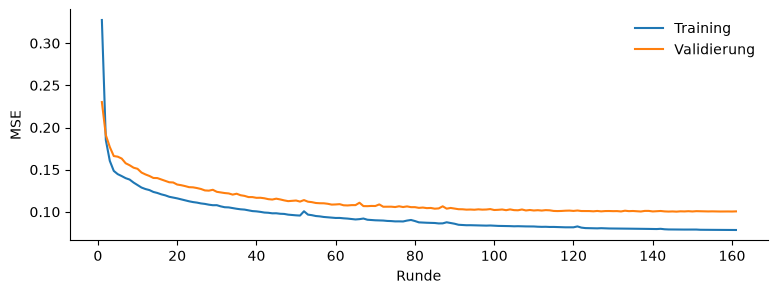

In [5]:
DATEI = MODELLE / "prognose_lstm.pt"
lern_idx = ziel_idx[tage.loc[ziel_idx, "abschnitt"].eq("Training").to_numpy()]
val_idx = ziel_idx[tage.loc[ziel_idx, "abschnitt"].eq("Validierung").to_numpy()]


def trainieren(modell, max_runden=200, geduld=15, stapel=512):
    torch.manual_seed(SEED)
    opt = torch.optim.Adam(modell.parameters(), lr=2e-3)
    plan = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4, min_lr=1e-5)
    vv, vz, vy = (t.to(GERAET) for t in eingaenge(x, val_idx))
    verlauf, bester, bester_zustand, ohne_besserung = [], np.inf, None, 0
    for runde in range(max_runden):
        modell.train()
        summe = 0.0
        for teil in np.array_split(np.random.default_rng(runde).permutation(lern_idx), max(1, len(lern_idx) // stapel)):
            tv, tz, ty = (t.to(GERAET) for t in eingaenge(x, teil))
            verlust = nn.functional.mse_loss(modell(tv, tz), ty)
            opt.zero_grad()
            verlust.backward()
            opt.step()
            summe += verlust.item() * len(teil)
        modell.eval()
        with torch.no_grad():
            val = nn.functional.mse_loss(modell(vv, vz), vy).item()
        verlauf.append({"runde": runde + 1, "training": summe / len(lern_idx), "validierung": val})
        plan.step(val)
        if val < bester - 1e-5:
            bester, ohne_besserung = val, 0
            bester_zustand = {k: w.detach().clone() for k, w in modell.state_dict().items()}
        else:
            ohne_besserung += 1
            if ohne_besserung >= geduld:
                break
    modell.load_state_dict(bester_zustand)
    return pd.DataFrame(verlauf)


if DATEI.exists() and not NEU_TRAINIEREN:
    gespeichert = torch.load(DATEI, map_location=GERAET)
    modell.load_state_dict(gespeichert["gewichte"])
    verlauf = pd.DataFrame(gespeichert["verlauf"])
    print(f"Gewichte geladen aus {DATEI.relative_to(ROOT)}")
else:
    start = time.time()
    verlauf = trainieren(modell)
    torch.save({"gewichte": modell.state_dict(), "verlauf": verlauf.to_dict("list")}, DATEI)
    print(f"Trainiert in {time.time() - start:.0f} s, gespeichert in {DATEI.relative_to(ROOT)}")
print(f"{len(lern_idx):,} Trainings- und {len(val_idx):,} Validierungstage; "
      f"bester Validierungsfehler {verlauf['validierung'].min():.4f} nach {verlauf['validierung'].idxmin() + 1} Runden")

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(verlauf["runde"], verlauf["training"], label="Training")
ax.plot(verlauf["runde"], verlauf["validierung"], label="Validierung")
ax.set_xlabel("Runde")
ax.set_ylabel("MSE")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Was macht diese Zelle?**
- Dieselbe Trainingsschleife wie in Notebook 20. Neu ist nur, dass die Stapel mit `eingaenge()`
  erst beim Lernen zusammengestellt werden: Alle Vorgeschichten auf einmal würden viel
  Speicher kosten, weil jeder Tag in sieben Vorgeschichten vorkommt.

## 5 · Wie gut ist die Vorhersage?

Ein Netz ist nur dann ein guter Wächter, wenn es besser vorhersagt als einfache Regeln.
Zwei naheliegende Vergleiche:

* **wie gestern:** Morgen verläuft genau wie heute.
* **Mittel der Woche:** Jede Stunde von morgen ist der Mittelwert dieser Stunde über die letzten 7 Tage.

Gemessen wird der mittlere absolute Fehler in echten Einheiten auf Tagen, die das
Netz nie zum Lernen gesehen hat.

In [6]:
def vorhersagen(feld_skaliert, idx, stapel=4096):
    modell.eval()
    teile = []
    with torch.no_grad():
        for start in range(0, len(idx), stapel):
            v, z, _ = eingaenge(feld_skaliert, idx[start:start + stapel])
            teile.append(modell(v.to(GERAET), z.to(GERAET)).cpu().numpy())
    p = np.concatenate(teile)
    rl = p[:, :, 0] * streuung["ruecklauf"] + mittel["ruecklauf"]                         # zurück in °C
    fl = p[:, :, 1] * tage.loc[idx, "zaehler"].map(fl_teiler).to_numpy()[:, None]         # zurück in l/h
    return rl, fl


zeilen = []
for abschnitt in ("Validierung", "Test (Sommer 2024)"):
    idx = ziel_idx[tage.loc[ziel_idx, "abschnitt"].eq(abschnitt).to_numpy()]
    rl, fl = vorhersagen(x, idx)
    echt = werte[idx]
    gestern = werte[idx - 1]
    woche = werte[idx[:, None] + np.arange(-VORGESCHICHTE, 0)].mean(axis=1)
    for name, rl_v, fl_v in (("LSTM", rl, fl), ("wie gestern", gestern[:, :, RL], gestern[:, :, FL]),
                             ("Mittel der Woche", woche[:, :, RL], woche[:, :, FL])):
        zeilen.append({"Abschnitt": abschnitt, "Verfahren": name, "Tage": len(idx),
                       "MAE Rücklauf [K]": np.abs(rl_v - echt[:, :, RL]).mean(),
                       "MAE Durchfluss [l/h]": np.abs(fl_v - echt[:, :, FL]).mean()})
guete = pd.DataFrame(zeilen).set_index(["Abschnitt", "Verfahren"])
guete.round(2)

Tage  MAE Rücklauf [K]  MAE Durchfluss [l/h]
Abschnitt          Verfahren                                                     
Validierung        LSTM              2532              3.87                 70.75
                   wie gestern       2532              6.23                 93.82
                   Mittel der Woche  2532              5.79                 97.39
Test (Sommer 2024) LSTM              6549              2.12                 78.18
                   wie gestern       6549              4.54                 70.67
                   Mittel der Woche  6549              4.15                 83.41

**Was macht diese Zelle?**
- `vorhersagen()` schickt beliebig viele Zieltage in Stapeln durch das Netz und rechnet in °C
  und l/h zurück.
- Die beiden Vergleichsverfahren brauchen kein Netz: „wie gestern“ ist der Vortag,
  „Mittel der Woche“ der stündliche Mittelwert der sieben Vortage.

**Ergebnis**

- **Rücklauf:** Das LSTM liegt im Mittel 3,9 K neben der Messung (Validierung über alle Jahreszeiten) bzw. 2,1 K (Sommer 2024). „Wie gestern“ liegt doppelt so weit daneben (6,2 bzw. 4,5 K). Für den Rücklauf hat das Netz also wirklich etwas gelernt: wie die Station auf Wetter und Vorlauf reagiert.
- **Durchfluss:** Über das Jahr ist das LSTM besser (71 gegen 94 l/h). **Im Sommer nicht:** Dort liegt es mit 78 l/h sogar etwas hinter „wie gestern“ (71 l/h). Im Sommer besteht der Durchfluss fast nur aus kurzen Warmwasser-Spitzen, und wann jemand duscht, kann kein Modell vorhersagen.
- Für den Wächter heißt das: Der Rücklauf ist der verlässlichere Kanal. Beim Durchfluss schaut er deshalb nur auf die Nacht (0–5 Uhr), wenn kaum jemand Warmwasser zapft.

## 6 · Von der Abweichung zur Warnung

Je Tag werden zwei Abweichungen berechnet, jeweils **gemessen minus vorhergesagt**:

* **Rücklauf:** mittlere Abweichung über den Tag [K] — ein falsch eingestellter Sollwert,
  ein hängender Fühler oder ein Bypass heben oder senken ihn;
* **Nachtdurchfluss:** mittlere Abweichung zwischen 0 und 5 Uhr [l/h] — nachts sollte kaum
  Wasser fließen; ein offenes Ventil zeigt sich hier zuerst.

Was „viel“ ist, hängt an der Station: Bei einem großen Haus schwankt der Durchfluss
mehr als bei einem kleinen. Deshalb wird jede Abweichung an der **normalen Schwankung
derselben Station** gemessen, ermittelt auf ihren Validierungstagen (robuster z-Wert mit
Median und MAD). Ein z-Wert von 6 heißt: sechsmal so weit weg wie üblich.

**Warnregel:** Ein Tag ist auffällig, wenn einer der beiden z-Werte über der Schwelle
liegt. Gewarnt wird erst, wenn **zwei Tage hintereinander** auffällig sind — ein einzelner
Ausreißer (Party, Urlaub, Messfehler) soll keinen Alarm auslösen.

In [7]:
def abweichungen(feld, idx):
    rl, fl = vorhersagen(skalieren(feld) if feld is not werte else x, idx)
    return pd.DataFrame({
        "zaehler": tage.loc[idx, "zaehler"].to_numpy(),
        "tag": tage.loc[idx, "tag"].to_numpy(),
        "res_rl": (feld[idx][:, :, RL] - rl).mean(axis=1),
        "res_fluss_nacht": (feld[idx][:, :6, FL] - fl[:, :6]).mean(axis=1),
    }, index=idx)


tag_abw = abweichungen(werte, ziel_idx)
tag_abw["abschnitt"] = tage.loc[ziel_idx, "abschnitt"].to_numpy()

# Normale Schwankung je Station aus den Validierungstagen (robust: Median und MAD)
kal = tag_abw[tag_abw["abschnitt"] == "Validierung"].groupby("zaehler").agg(
    tage=("res_rl", "size"),
    rl_mitte=("res_rl", "median"), rl_mad=("res_rl", lambda s: 1.4826 * (s - s.median()).abs().median()),
    fl_mitte=("res_fluss_nacht", "median"), fl_mad=("res_fluss_nacht", lambda s: 1.4826 * (s - s.median()).abs().median()))
kal = kal[kal["tage"] >= 10]
kal["rl_mad"] = kal["rl_mad"].clip(lower=0.5)      # mindestens 0,5 K
kal["fl_mad"] = kal["fl_mad"].clip(lower=5.0)      # mindestens 5 l/h


def z_werte(abw):
    k = kal.reindex(abw["zaehler"]).to_numpy()
    spalten = list(kal.columns)
    abw = abw.copy()
    abw["z_rl"] = (abw["res_rl"] - k[:, spalten.index("rl_mitte")]) / k[:, spalten.index("rl_mad")]
    abw["z_fluss"] = (abw["res_fluss_nacht"] - k[:, spalten.index("fl_mitte")]) / k[:, spalten.index("fl_mad")]
    return abw


def warnungen(abw, schwelle):
    # auffällig: einer der beiden z-Werte über der Schwelle; Warnung: zwei auffällige Tage hintereinander
    auff = (abw["z_rl"].abs() >= schwelle) | (abw["z_fluss"].abs() >= schwelle)
    vortag_auff = auff.groupby(abw["zaehler"]).shift(1, fill_value=False)
    vortag_direkt = abw.groupby("zaehler")["tag"].diff().eq(pd.Timedelta(days=1))
    return auff & vortag_auff & vortag_direkt


tag_abw = z_werte(tag_abw)
print(f"Normale Schwankung für {len(kal)} Zähler bestimmt (mind. 10 Validierungstage)")
print(f"typische Schwankung (Median über Zähler): Rücklauf {kal['rl_mad'].median():.2f} K, Nachtdurchfluss {kal['fl_mad'].median():.1f} l/h")
tag_abw.dropna().head().round({"res_rl": 2, "res_fluss_nacht": 2, "z_rl": 2, "z_fluss": 2})

Normale Schwankung für 67 Zähler bestimmt (mind. 10 Validierungstage)
typische Schwankung (Median über Zähler): Rücklauf 1.56 K, Nachtdurchfluss 18.2 l/h


,zaehler,tag,res_rl,res_fluss_nacht,abschnitt,z_rl,z_fluss
7,41704231,2022-11-20,-0.85,-0.02,Validierung,-1.24,-0.0
8,41704231,2022-11-21,0.10,-0.01,Training,0.21,-0.0
9,41704231,2022-11-22,-1.51,-0.01,Training,-2.24,-0.0
10,41704231,2022-11-23,1.65,-0.01,Training,2.56,-0.0
11,41704231,2022-11-24,-0.55,-0.01,Training,-0.79,-0.0


**Was macht diese Zelle?**
- `abweichungen()` sagt die Zieltage vorher und berechnet je Tag die beiden Abweichungen.
  Sie nimmt ein Feld als Eingang, damit sie später auch auf Daten mit eingerechneten Fehlern
  läuft.
- `kal` ist je Station die normale Lage (Median) und Schwankung (MAD × 1,4826, entspricht
  bei Normalverteilung der Standardabweichung). Damit ruhige Stationen nicht bei jeder
  Kleinigkeit warnen, gibt es eine Untergrenze von 0,5 K bzw. 5 l/h.
- `warnungen()` setzt die Regel um: auffällig an diesem **und** am direkt vorhergehenden Tag.

## 7 · Prüfung mit eingerechneten Fehlern

Echte neue Fehler mit bekanntem Beginn gibt es in den Daten nicht. Deshalb werden
Fehler **eingerechnet**: In der sauberen Testzeit (Sommer 2024) wird bei jeder Station ab
einem zufälligen Tag acht Tage lang ein Fehler in die Messwerte geschrieben. Dann wird
gezählt, bei wie vielen Stationen der Wächter innerhalb dieser acht Tage warnt.

| Fehler | was eingerechnet wird | Physik |
|---|---|---|
| **Bypass 50 / 150 l/h** | Durchfluss + 50 bzw. 150 l/h zu jeder Stunde; der Rücklauf mischt sich mit Vorlaufwasser | Ventil steht offen, Wasser läuft ungenutzt durch |
| **Fühler hängt** | Rücklauf bleibt ab dem ersten Tag auf seinem Wert stehen | Temperaturfühler defekt |
| **Sollwert +5 K** | Rücklauf + 5 K, wenn Wasser fließt | Regler falsch eingestellt |
| **ohne** | nichts | jede Warnung ist ein **Fehlalarm** |

In [8]:
FENSTER = 8
rng = np.random.default_rng(SEED)
test = tag_abw[(tag_abw["abschnitt"] == "Test (Sommer 2024)") & tag_abw["zaehler"].isin(kal.index)]
starts = []
for zaehler, g in test.groupby("zaehler"):
    # Starttage, ab denen acht aufeinanderfolgende Testtage vorhanden sind
    moeglich = [i for k, i in enumerate(g.index[:-FENSTER + 1]) if (g["tag"].iloc[k + FENSTER - 1] - g["tag"].iloc[k]).days == FENSTER - 1]
    starts += list(rng.choice(moeglich, size=min(3, len(moeglich)), replace=False)) if moeglich else []
fenster = np.array([np.arange(s, s + FENSTER) for s in starts])
print(f"{len(starts)} Testfenster bei {test.loc[starts, 'zaehler'].nunique()} Zählern")


def einrechnen(fehler):
    feld = werte.copy()
    for f in fenster:
        teil = feld[f]
        if fehler.startswith("Bypass"):
            extra = float(fehler.split()[1])
            teil[:, :, RL] = (teil[:, :, RL] * teil[:, :, FL] + teil[:, :, VL] * extra) / (teil[:, :, FL] + extra)
            teil[:, :, FL] += extra
        elif fehler == "Fühler hängt":
            teil[:, :, RL] = teil[0, 0, RL]
        elif fehler == "Sollwert +5 K":
            teil[:, :, RL] += np.where(teil[:, :, FL] > 1, 5.0, 0.0)
        feld[f] = teil
    return feld


FEHLER = ["ohne", "Bypass 50", "Bypass 150", "Fühler hängt", "Sollwert +5 K"]
SCHWELLEN = [3, 4, 6, 8]
zeilen = []
for fehler in FEHLER:
    abw = z_werte(abweichungen(einrechnen(fehler), fenster.ravel()))
    abw["fenster"] = np.repeat(np.arange(len(fenster)), FENSTER)
    for s in SCHWELLEN:
        getroffen = warnungen(abw, s).groupby(abw["fenster"]).any()
        zeilen.append({"Fehler": fehler, "Schwelle": s, "Warnung in 8 Tagen": getroffen.mean()})
injektion = pd.DataFrame(zeilen).pivot(index="Fehler", columns="Schwelle", values="Warnung in 8 Tagen").reindex(FEHLER)
injektion.round(2)

180 Testfenster bei 60 Zählern


Schwelle,3,4,6,8
Fehler,,,,
ohne,0.05,0.02,0.00,0.00
Bypass 50,0.49,0.36,0.21,0.11
Bypass 150,0.90,0.81,0.63,0.51
Fühler hängt,0.38,0.25,0.07,0.02
Sollwert +5 K,0.21,0.10,0.02,0.01


**Was macht diese Zelle?**
- Sucht je Station bis zu drei zufällige Startpunkte in der Testzeit, ab denen acht Tage am
  Stück vorliegen.
- `einrechnen()` schreibt den Fehler in eine Kopie der **ungeskalierten** Messwerte. Beim
  Bypass mischt sich der Rücklauf mit dem durchlaufenden Vorlaufwasser — so, wie es in der
  Station tatsächlich passieren würde.
- Die Vorgeschichte des Netzes enthält ab dem zweiten Tag selbst schon den Fehler. Das ist
  realistisch: Auch im Betrieb sieht der Wächter die gestörten Tage als Vorgeschichte.
- Die Tabelle zeigt je Fehler und Schwelle den Anteil der Fenster mit mindestens einer Warnung.
  Die Zeile „ohne“ ist die **Fehlalarmrate**.

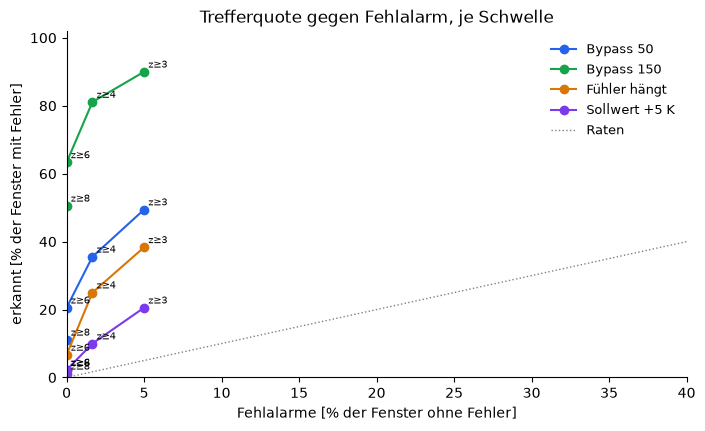

Gewählte Schwelle für den Betrieb: z ≥ 3 (kleinste mit höchstens 10 % Fehlalarmen in 8 Tagen)


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for fehler, farbe in zip(FEHLER[1:], ["#2563EB", "#16A34A", "#D97706", "#7C3AED"]):
    ax.plot(injektion.loc["ohne"] * 100, injektion.loc[fehler] * 100, "o-", color=farbe, label=fehler)
    for s in SCHWELLEN:
        ax.annotate(f"z≥{s}", (injektion.loc["ohne", s] * 100, injektion.loc[fehler, s] * 100), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.plot([0, 100], [0, 100], ":", color="grey", lw=1, label="Raten")
ax.set_xlim(0, max(40, injektion.loc["ohne"].max() * 110))
ax.set_ylim(0, 102)
ax.set_xlabel("Fehlalarme [% der Fenster ohne Fehler]")
ax.set_ylabel("erkannt [% der Fenster mit Fehler]")
ax.set_title("Trefferquote gegen Fehlalarm, je Schwelle")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

SCHWELLE = min([s for s in SCHWELLEN if injektion.loc["ohne", s] <= 0.10], default=max(SCHWELLEN))
print(f"Gewählte Schwelle für den Betrieb: z ≥ {SCHWELLE} (kleinste mit höchstens 10 % Fehlalarmen in 8 Tagen)")

**Was macht diese Zelle?**
- Jede Linie ist ein Fehler, jeder Punkt eine Schwelle: x = Fehlalarme, y = Treffer. Gut ist
  oben links. Eine niedrigere Schwelle bringt immer **mehr Treffer und mehr Fehlalarme** —
  fair vergleichen lässt sich nur bei gleicher Fehlalarmrate.
- Für den Betrieb wird die kleinste Schwelle gewählt, bei der höchstens jedes zehnte Fenster
  ohne Fehler einen Fehlalarm hat.

**Ergebnis**

- **Fehlalarme sind selten:** Bei z ≥ 3 hat in der Testzeit nur jedes zwanzigste Fenster ohne Fehler eine Warnung (5 %), ab z ≥ 6 keines mehr.
- **Ein großer Bypass wird fast immer gefunden:** 150 l/h zu 90 % innerhalb von acht Tagen. Ein kleiner (50 l/h) zur Hälfte.
- **Ein hängender Fühler** wird zu 38 % erkannt. Das ist weniger, als man erwarten würde: Im Sommer schwankt der Rücklauf ohnehin wenig, ein eingefrorener Wert fällt dann kaum auf.
- **Ein um 5 K verstellter Sollwert** wird nur zu 21 % erkannt. 5 K liegen im Bereich der normalen Schwankung von Tag zu Tag, und das Netz bekommt den höheren Rücklauf ab dem zweiten Tag auch als Vorgeschichte und gewöhnt sich daran.
- Gewählt für den Betrieb: **z ≥ 3**. Höher bringt kaum weniger Fehlalarme, aber deutlich weniger Treffer.

## 8 · Echte Begehungen: Merkt der Wächter, dass sich etwas verändert hat?

Bei der Begehung wurde an vielen Stationen etwas verstellt oder getauscht. Ein guter
Wächter sollte das als **Veränderung** bemerken — er kennt ja nur das Verhalten vorher.
Verglichen wird der Anteil der Stationen mit Warnung in den **14 Tagen nach der
Begehung** mit dem Anteil bei nie begangenen Stationen in denselben Kalenderwochen.

In [10]:
NACH = 14
betrieb = tag_abw[tag_abw["zaehler"].isin(kal.index)].copy()
betrieb["warnung"] = warnungen(betrieb, SCHWELLE)

begangen = labels.dropna(subset=["erste_begehung"])
begangen = begangen[begangen.index.isin(kal.index)]
nie = sorted(set(kal.index) - set(labels.index))
daten_pool = begangen["erste_begehung"].to_numpy()


def warnt_im_fenster(zaehler, von):
    t = betrieb[(betrieb["zaehler"] == zaehler) & (betrieb["tag"] >= von) & (betrieb["tag"] < von + pd.Timedelta(days=NACH))]
    return t["warnung"].any() if len(t) >= 7 else np.nan


zeilen = [{"Gruppe": "begangen", "zaehler": z, "ventil": begangen.loc[z, "ventil"],
           "warnung": warnt_im_fenster(z, begangen.loc[z, "erste_begehung"])} for z in begangen.index]
rng = np.random.default_rng(SEED)
for z in nie:
    for datum in rng.choice(daten_pool, size=3, replace=False):
        zeilen.append({"Gruppe": "nie begangen (Vergleich)", "zaehler": z, "ventil": np.nan, "warnung": warnt_im_fenster(z, pd.Timestamp(datum))})
nach_begehung = pd.DataFrame(zeilen).dropna(subset=["warnung"])
nach_begehung["warnung"] = nach_begehung["warnung"].astype(bool)
nach_begehung["Teilgruppe"] = np.where(nach_begehung["ventil"] == True, "begangen, Ventil getauscht",
                                       np.where(nach_begehung["Gruppe"] == "begangen", "begangen, anderer Eingriff", "nie begangen (Vergleich)"))
nach_begehung.groupby("Teilgruppe")["warnung"].agg(Fenster="size", mit_Warnung="sum", Anteil="mean").round(2)

,Fenster,mit_Warnung,Anteil
Teilgruppe,,,
"begangen, Ventil getauscht",7,2,0.29
"begangen, anderer Eingriff",21,7,0.33
nie begangen (Vergleich),49,9,0.18


**Was macht diese Zelle?**
- Wendet die Warnregel mit der gewählten Schwelle auf alle Tage an.
- Je begangener Station: Gab es in den 14 Tagen ab der Begehung eine Warnung? Fenster mit
  weniger als 7 vorhergesagten Tagen zählen nicht.
- Vergleich: Für jede nie begangene Station werden drei echte Begehungsdaten anderer
  Stationen gezogen und dieselbe Frage gestellt. So stimmen Jahreszeit und Wetter überein.

**Ergebnis**

- Nach einem Ventiltausch warnte der Wächter bei 2 von 7 Stationen innerhalb von 14 Tagen, nach anderen Eingriffen bei 7 von 21 (33 %).
- **Aber:** Auch bei nie begangenen Stationen gibt es in denselben Kalenderwochen bei 18 % der Fenster eine Warnung. Der Unterschied ist bei so wenigen Fenstern nicht abzusichern.
- **Warum so viele Warnungen ohne Begehung?** Die Schwelle wurde im ruhigen Sommer 2024 gewählt. Ab Oktober schwanken die Stationen stärker, und z ≥ 3 ist dann zu empfindlich (siehe Abschnitt 9). In der Vorarbeit wurde das mit einem Faktor je Jahreszeit gelöst. Das wäre der nächste Schritt.
- **Das Beispiel darunter** ist Zähler 68956351, der „bekannte Fall“ aus [`14_monitor`](14_monitor.ipynb) und [`17_normalverhaltensmodell`](17_normalverhaltensmodell.ipynb). Vor der Begehung liegt alles im grauen Normalbereich. Direkt danach springt der Rücklauf weit heraus (z bis −15 und +10), und es folgen mehrere Warnungen. Der Wächter sieht also, dass die Station ab diesem Tag anders arbeitet.

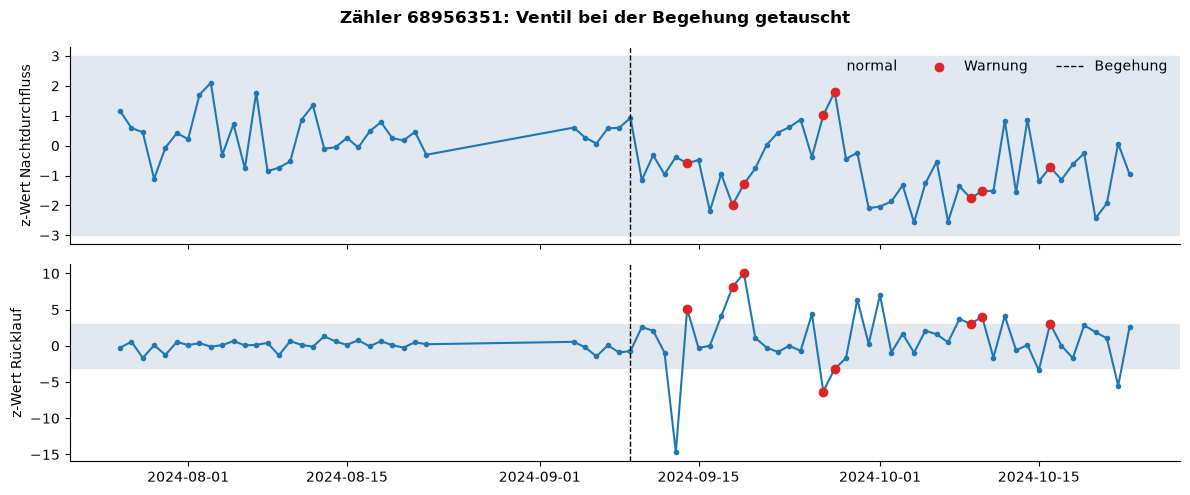

In [11]:
beispiel = nach_begehung[(nach_begehung["Teilgruppe"] == "begangen, Ventil getauscht") & nach_begehung["warnung"]]
if len(beispiel):
    zaehler = beispiel["zaehler"].iloc[0]
    datum = begangen.loc[zaehler, "erste_begehung"]
    t = betrieb[(betrieb["zaehler"] == zaehler) & (betrieb["tag"] >= datum - pd.Timedelta(days=45)) & (betrieb["tag"] < datum + pd.Timedelta(days=45))]
    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    for ax, spalte, titel in ((axes[0], "z_fluss", "z-Wert Nachtdurchfluss"), (axes[1], "z_rl", "z-Wert Rücklauf")):
        ax.plot(t["tag"], t[spalte], "o-", ms=3)
        ax.axhspan(-SCHWELLE, SCHWELLE, color="#E2E8F0", label="normal")
        ax.scatter(t.loc[t["warnung"], "tag"], t.loc[t["warnung"], spalte], color="#DC2626", zorder=3, label="Warnung")
        ax.axvline(datum, color="black", ls="--", lw=1, label="Begehung")
        ax.set_ylabel(titel)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, ncol=3)
    fig.suptitle(f"Zähler {zaehler}: Ventil bei der Begehung getauscht", fontweight="bold")
    fig.tight_layout()
    plt.show()

**Was macht diese Zelle?**
- Zeigt für eine Station, an der das Ventil getauscht wurde und der Wächter gewarnt hat, die
  beiden z-Werte rund um die Begehung. Grau ist der normale Bereich, rot sind die Tage mit
  Warnung.

## 9 · Haus oder Netz?

Steigt bei vielen Stationen am selben Tag der Rücklauf, liegt es selten an jedem einzelnen
Haus — eher am Netz (Vorlauftemperatur, Pumpen, Umstellung in der Heizzentrale). Der
Wächter kann das unterscheiden, indem er zählt, **wie viele Stationen am selben Tag warnen**.

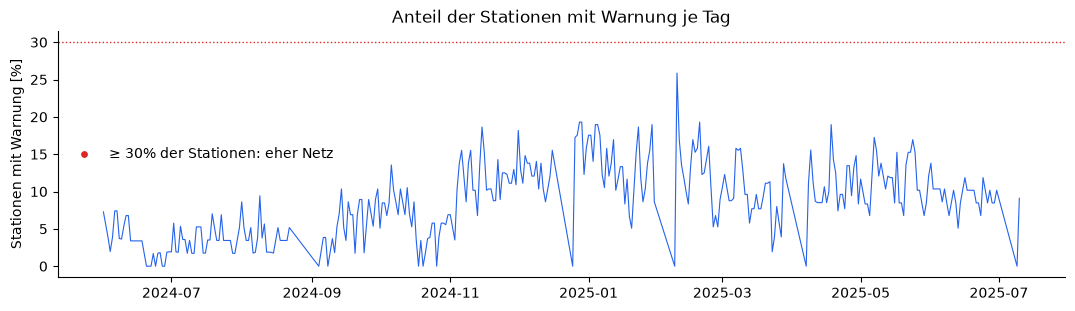

0 von 361 Tagen gelten als Netz-Tage; 0% aller Warnungen fallen auf solche Tage


In [12]:
je_tag = betrieb[betrieb["abschnitt"].isin(["Test (Sommer 2024)", "nach der Begehung"])].groupby("tag")["warnung"].agg(["mean", "size"])
je_tag = je_tag[je_tag["size"] >= 20]
NETZ_ANTEIL = 0.3
netz_tage = je_tag[je_tag["mean"] >= NETZ_ANTEIL]
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.plot(je_tag.index, je_tag["mean"] * 100, lw=0.8, color="#2563EB")
ax.scatter(netz_tage.index, netz_tage["mean"] * 100, color="#DC2626", s=15, zorder=3, label=f"≥ {NETZ_ANTEIL:.0%} der Stationen: eher Netz")
ax.axhline(NETZ_ANTEIL * 100, color="#DC2626", ls=":", lw=1)
ax.set_ylabel("Stationen mit Warnung [%]")
ax.set_title("Anteil der Stationen mit Warnung je Tag")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
anteil_netz = betrieb.loc[betrieb["warnung"] & betrieb["tag"].isin(netz_tage.index)].shape[0] / max(betrieb["warnung"].sum(), 1)
print(f"{len(netz_tage)} von {len(je_tag)} Tagen gelten als Netz-Tage; {anteil_netz:.0%} aller Warnungen fallen auf solche Tage")

**Was macht diese Zelle?**
- Zählt je Kalendertag den Anteil der Stationen mit Warnung (nur Tage, an denen mindestens
  20 Stationen vorhergesagt wurden).
- Tage, an denen mindestens 30 % der Stationen gleichzeitig warnen, gelten als **Netz-Tage**.
  Eine Warnung an einem solchen Tag geht nicht an den Hauseigentümer, sondern an den Netzbetreiber.

**Ergebnis**

- An keinem Tag warnten 30 % der Stationen gleichzeitig. Der höchste Wert lag bei 26 % am 9. Februar 2025. Ein Netzereignis, das viele Stationen zugleich trifft, gibt es in diesen Daten also nicht. Die Warnungen sind Einzelfälle der Häuser.
- **Der Anteil steigt aber über die Zeit:** Im Sommer 2024 warnen im Median 3 % der Stationen am Tag, im Winter 24/25 rund 13 %, und auch im Juni 2025 noch 10 %. Zwei Gründe:
  - Im Winter schwanken die Stationen stärker; die Schwelle passt zum Sommer.
  - Viele Stationen arbeiten **nach der Begehung dauerhaft anders** als in der Zeit, aus der der Wächter ihr Normalverhalten kennt. Er meldet dann zu Recht eine Veränderung, aber immer wieder dieselbe.
- Für den Betrieb heißt das: Nach einem bekannten Eingriff muss der Wächter die Station neu kennenlernen (neue normale Schwankung, im besten Fall nachtrainiert).

## 10 · Ergebnis speichern

In [13]:
aus = betrieb[["zaehler", "tag", "abschnitt", "res_rl", "res_fluss_nacht", "z_rl", "z_fluss", "warnung"]]
aus.to_csv(PROCESSED / "prognose_tage.csv", index=False)
print(f"prognose_tage.csv: {len(aus):,} Zähler-Tage von {aus['zaehler'].nunique()} Zählern")

prognose_tage.csv: 48,470 Zähler-Tage von 67 Zählern


**Was macht diese Zelle?**
- Speichert Abweichung, z-Werte und Warnung je Zähler und Tag. Notebook 22 fasst die Tage
  **vor** der Begehung je Station zusammen und nutzt sie als Merkmale.

## Zusammenfassung & Bewertung

### Was dieses Notebook geliefert hat

Ein Encoder–Decoder-LSTM (35.000 Gewichte, 43 Sekunden Training), das für 67 Stationen jeden Tag Rücklauf und Durchfluss vorhersagt. Dazu eine Warnregel (z ≥ 3 an zwei Tagen hintereinander) und `prognose_tage.csv` mit Abweichung, z-Werten und Warnung je Zähler und Tag.

| Prüfung | Ergebnis | Bewertung |
|---|---|---|
| Vorhersage Rücklauf | 3,9 K gegen 6,2 K („wie gestern“) | **deutlich besser als einfache Regeln** |
| Vorhersage Durchfluss im Sommer | 78 gegen 71 l/h | **nicht besser** (Warmwasser-Spitzen) |
| Fehlalarme im Sommer | 5 % der 8-Tage-Fenster | **niedrig** |
| Bypass 150 / 50 l/h | 90 % / 49 % erkannt | **stark / mittel** |
| Fühler hängt, Sollwert +5 K | 38 % / 21 % | **schwach** |
| Veränderung nach echten Begehungen | 29–33 % gegen 18 % ohne Begehung | **nicht abgesichert** |
| Haus oder Netz | kein Netz-Tag in den Daten | **nicht prüfbar** |

### Wie das Ergebnis einzuordnen ist

- **Der Wächter ist ein Werkzeug für neue Fehler.** Ein Ventil, das plötzlich offen steht, findet er in den meisten Fällen innerhalb einer Woche, und zwar das ganze Jahr über, nicht erst im Sommer. Fehler, die es schon immer gab, sieht er nicht, weil er jede Station mit sich selbst vergleicht. Dafür sind Notebook 20 und 22 da.
- **Die größte Schwäche ist die Einstellung im Dauerbetrieb.** Die Schwelle passt zum Sommer; im Winter warnt der Wächter zu oft. Und nach einer Begehung meldet er dieselbe Veränderung immer wieder, weil er die Station nur von vorher kennt. Ein Faktor je Jahreszeit (in der Vorarbeit umgesetzt) und ein Neukalibrieren nach jedem bekannten Eingriff wären die nächsten Schritte.
- **Kleine Fehler gehen im Rauschen unter.** 5 K mehr Rücklauf liegen in der normalen Schwankung von Tag zu Tag. Dafür sind Vergleiche über Wochen oder Kennlinien (Notebook 14 und 17) besser geeignet.
- Notebook 22 nutzt die Abweichungen **vor** der Begehung als zusätzliche Merkmale: Eine Station, die schon im Sommer 2024 oft vom Erwarteten abwich, ist vielleicht auch bei der Begehung auffällig.